In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, root_mean_squared_error
from xgboost import XGBRegressor

In [2]:
# 3. Load dataset
df = pd.read_csv("../../data/data_with_features.csv", parse_dates=['observation_date'])
df = df.sort_values('observation_date')

In [3]:
df['lag1'] = df['cumulative_mite_count'].shift(1).fillna(0)
df['lag2'] = df['cumulative_mite_count'].shift(2).fillna(0)
df['lag3'] = df['cumulative_mite_count'].shift(3).fillna(0)

In [4]:
# 4. Features and target
features = ['initial_female_count', 'leaf_area_cm2', 'population_density', 'days_since_introduction']
target = 'cumulative_mite_count'

X = df[features]
y = df[target]


In [5]:
# 5. Target transformation (log)
y_log = np.log1p(y)  # log(1 + y)

In [6]:
# 6. Feature interactions / polynomial features
poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
X_poly = poly.fit_transform(X)

In [7]:
# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_poly)

In [8]:
# 7. Train-test split (time-based)
train_size = int(len(df) * 0.8)
X_train, X_test = X_scaled[:train_size], X_scaled[train_size:]
y_train, y_test = y_log[:train_size], y_log[train_size:]

In [9]:
# 8. XGBoost model with hyperparameter tuning
xgb = XGBRegressor(objective='reg:squarederror', random_state=42)
param_grid = {
    'n_estimators': [200, 300],
    'max_depth': [3, 5],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.8],
    'colsample_bytree': [0.8]
}

grid = GridSearchCV(xgb, param_grid, cv=3, scoring='r2', verbose=1)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
print("Best parameters:", grid.best_params_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300, 'subsample': 0.8}


In [10]:
# 9. Predict on test set
y_pred_log = best_model.predict(X_test)
y_pred = np.expm1(y_pred_log)  # invert log-transform

# Metrics
mse = mean_squared_error(y[train_size:], y_pred)
mae = mean_absolute_error(y[train_size:], y_pred)
rmse = root_mean_squared_error(y[train_size:], y_pred)
r2 = r2_score(y[train_size:], y_pred)

print(f"Test Metrics: MSE: {mse}, MAE: {mae}, R²: {r2}, rmse: {rmse}")

Test Metrics: MSE: 7641.47509765625, MAE: 68.26030731201172, R²: 0.5832293629646301, rmse: 87.41553497314453


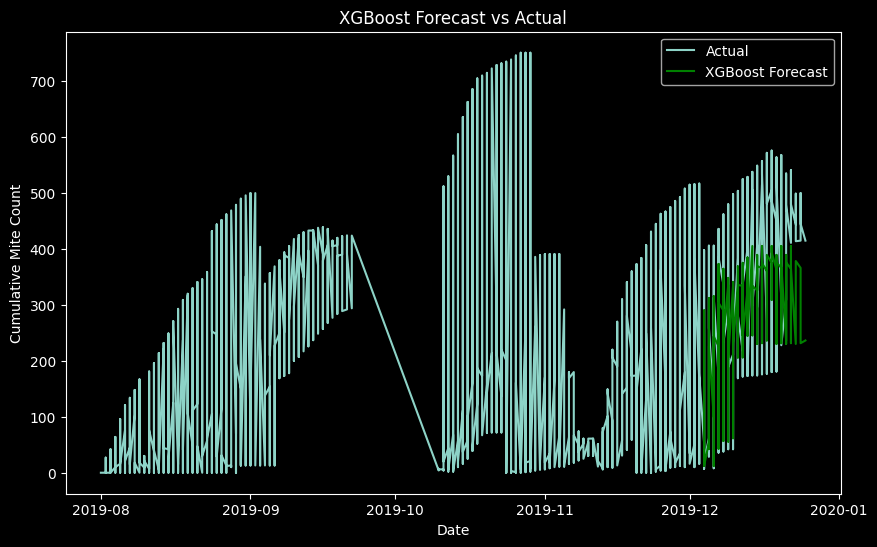

In [11]:
# 10. Plot actual vs predicted
plt.figure(figsize=(10,6))
plt.plot(df['observation_date'], y, label='Actual')
plt.plot(df['observation_date'][train_size:], y_pred, label='XGBoost Forecast', color='green')
plt.xlabel('Date')
plt.ylabel('Cumulative Mite Count')
plt.title('XGBoost Forecast vs Actual')
plt.legend()
plt.show()

In [12]:
num_days = 30
initial_female_count =10
leaf_area_cm2 = 60

future_df = pd.DataFrame({
    'initial_female_count': [initial_female_count]*num_days,
    'leaf_area_cm2': [leaf_area_cm2]*num_days,
    'population_density': [initial_female_count / leaf_area_cm2]*num_days,
    'days_since_introduction': list(range(1, num_days+1))
})

# Polynomial features and scaling
future_poly = poly.transform(future_df)
future_scaled = scaler.transform(future_poly)

# Predict future
future_log_pred = best_model.predict(future_scaled)
future_pred = np.expm1(future_log_pred)

print("Forecast for days 1–15:", future_pred)


Forecast for days 1–15: [ 15.376133  67.988785 105.98279  145.65627  143.46259  146.2509
 149.789    162.15611  178.82947  246.16167  256.5463   254.25208
 271.14542  291.61935  310.51114  326.3528   325.299    329.82358
 334.48798  377.3711   344.01483  384.03888  384.7981   380.5475
 371.72852  364.31924  311.49496  302.22385  303.23245  300.6456  ]


In [13]:
import pickle

# Create a dictionary containing all the components
pipeline_components = {
    'model': best_model,
    'poly_transformer': poly,
    'scaler': scaler
}

# Save the entire dictionary to a single .pkl file
with open('population_prediction_pipeline.pkl', 'wb') as file:
    pickle.dump(pipeline_components, file)

print("Pipeline components saved to 'population_prediction_pipeline.pkl'")

Pipeline components saved to 'population_prediction_pipeline.pkl'
